<a href="https://colab.research.google.com/github/Clemmenttine/analysis-everpeak/blob/main/S5_ladb_mobility_economy_project_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**.
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [ ]:
# importar librerías
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv') #completa el código

In [ ]:
# mostrar las primeras 5 filas de traffic
traffic.head()


,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [ ]:
# mostrar las primeras 5 filas de eco
eco.head()

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"


**Tip:** Si no usas `print()` la tabla se vera mejor.


---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [ ]:
# Examinar la estructura de traffic
traffic.info()
traffic.head(3)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtype

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232


En la estructura del DF traffic, se observa que:
- Hay 12 columnas en total y 1004464 registros. Hay 384 ciudades y 55 paises en el Data Set.
- Las columnas `UpdateTimeUTC` y `UpdateTimeUTC` son de tipo datetime y fueron leidas como object.
- Están completos los registros, ya que repsenta 1004464 non-null

In [ ]:
# Examinar la estructura de eco
eco.info()
eco.head(3)



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


En la estructura del DF eco, se observa que:
- Hay 30 filas y 7 columnas y todas están completas. Son 7 paises y 15 ciudades en este data set.
- Hay columnas numéricas que fueron tomadas como objeto por lo tanto hay que convertirlas a (float64). Estas son: city GDP/capita, pm2.5, unemployment % y population

### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [ ]:
# Estandarizar los nombres de las columnas de traffic
#tu código aquí
#Se cambian todos los nombres de las columnas a este formato para que sean más lelgibles.

traffic = traffic.rename (columns={
    'Country': 'country',
    'City': 'city',
    'UpdateTimeUTC': 'update_time_utc',
    'JamsDelay': 'jams_delay',
    'TrafficIndexLive': 'traffic_index_live',
    'JamsLengthInKms': 'jams_length_in_kms',
    'JamsCount': 'jams_count',
    'TrafficIndexWeekAgo': 'traffic_index_week_ago',
    'UpdateTimeUTCWeekAgo': 'update_time_utc_week_ago',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins',
    'TravelTimeHistoricPer10KmsMins': 'travel_time_historic_per_10kms_mins',
    'MinsDelay': 'mins_delay'
})

# verificar cambios
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_in_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins',
       'travel_time_historic_per_10kms_mins', 'mins_delay'],
      dtype='object')

In [ ]:
# Estandarizar los nombres de las columnas de eco
#tu código aquí
eco = eco.rename(columns={
    'Year': 'year',
    'City': 'city',
    'Country': 'country',
    'City GDP/capita': 'city_gdp_capita',
    'Unemployment %': 'unemployment_pct',
    'PM2.5 (μg/m³)': 'pm25_ug_m3',
    'Population (M)': 'population_m'
})
# verificar cambios
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25_ug_m3', 'population_m'],
      dtype='object')


### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convierte las columnas de fecha de `traffic` a formato `datetime`. Haz el cambio a prueba de errores.
- En el dataset `eco`, limpia los valores numéricos:
    - En `city_gdp_capita`: elimina separadores de miles (`.`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: elimina el símbolo de porcentaje (`%`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crea una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


<details>
<summary>Haz clic para ver la pista</summary>
para eliminar símbolos, puedes reemplazarlos por un texto vacío.

In [ ]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'])
traffic['update_time_utc_week_ago'] = pd.to_datetime(traffic['update_time_utc_week_ago'])

# verificar el cambio
traffic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                               Non-Null Count    Dtype         
---  ------                               --------------    -----         
 0   country                              1004464 non-null  object        
 1   city                                 1004464 non-null  object        
 2   update_time_utc                      1004464 non-null  datetime64[ns]
 3   jams_delay                           1004464 non-null  float64       
 4   traffic_index_live                   1004464 non-null  float64       
 5   jams_length_in_kms                   1004464 non-null  float64       
 6   jams_count                           1004464 non-null  float64       
 7   traffic_index_week_ago               1004464 non-null  float64       
 8   update_time_utc_week_ago             1004464 non-null  datetime64[ns]
 9   travel_time_live_per_10kms_mins      1004464 non-null  fl

In [ ]:

# Limpia separadores y convierte columnas numéricas en eco
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco['unemployment_pct'] = eco['unemployment_pct'] = eco['unemployment_pct'].astype(str).str.replace('%', '').str.replace(',', '.').astype(float)
eco['population_m'] = eco['population_m'] = eco['population_m'].astype(str).str.replace(',', '.').astype(float)

# Calcula la población total en unidades absolutas (Multiplica * 1000000)
eco['population'] = eco['population_m']*1000000

# verificar el cambio
eco.info()
eco.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25_ug_m3        30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25_ug_m3,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0



---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [ ]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = traffic['update_time_utc'].dt.year

# Verificar cambio
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [ ]:
# Filtra los registros del año 2024

traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25_ug_m3,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0



---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


<details>
<summary>Haz clic para ver la pista</summary>
Usa ".agg()" para aplicar funciones de promedio. Al final, reinicia el índice para mantener las columnas de la agrupación como variables (no índices).

In [ ]:
# Calcular los  promedios de trafico por ciudad, país y año
# se crea una agrupación llamada traffic_metrics que una todas las variables de tráfico del dataset
traffic_metrics = [
   'jams_delay',
       'traffic_index_live', 'jams_length_in_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins',
       'travel_time_historic_per_10kms_mins', 'mins_delay'
]
traffic_city_year_2024 =  (
    traffic_2024
    .groupby(['city', 'country', 'year'])[traffic_metrics]
    .mean()
    .reset_index()
)
# Mostrar resultado
traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,15.821025,16.267977,15.493804,0.774172
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,21.874836,13.397861,12.604894,0.792968
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,17.445227,15.219292,14.724016,0.495276
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,14.295209,9.829092,9.689328,0.139764
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,22.508810,15.879694,14.749945,1.129749


### 🧠 **Momento de reflexión**

¡Excelente trabajo hasta aquí!

Ahora que ya tienes los promedios anuales por ciudad, es momento de **observarlos** con atención.

Piensa:

- ¿Cuál crees que tiene el mayor tiempo promedio de tráfico?
- ¿Será una ciudad de **Europa**, de **Latinoamérica** o de **otra región** del mundo?

Para descubrirlo, ejecuta esta línea de código:

`traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)`


🔍 Observa qué ciudad aparece en los primeros lugares.

¿Te sorprenden los resultados? , ¿Coinciden con lo que imaginabas?

In [ ]:
# tu código aquí
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,36.443813,21.809092,19.953550,1.855542
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,37.441779,22.443778,21.745626,0.698152
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,29.337407,18.505043,17.108691,1.396351
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,30.827376,17.714139,16.388979,1.325160
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,68.628341,27.134629,24.664734,2.469894
...,...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,15.975631,16.226009,15.592715,0.633294
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,14.470460,15.746717,15.244916,0.501802
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,10.938767,11.662590,11.467639,0.194951
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,6.666082,9.467150,9.484694,-0.017544


La ciudad con el mayor tiempo promedio de tráfico es Ciudad de México lo cual no sorprende ya que es un lugar famoso por sus colapsos viales. le siguen Tokyo, Nueva York y Londres que son ciudades muy grandes que igual que México reciben muchos habitantes flotantes (que trabajan o visitan pero no duermen allá) y hacen que la ciudad colapse. Me sorprende Manila, pero la verdad es por que no sé mucho sobre esa ciudad.


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


<details>
<summary>Haz clic para ver la pista</summary>
Aplica una unión de tipo "inner" para mantener las ciudades y años presentes en ambos datasets.

In [ ]:
# Seleccionar columnas clave de tráfico y economía y las guardameos en left y right cols
left_cols = ['city', 'country','year','jams_delay','traffic_index_live',
             'jams_length_in_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_historic_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25_ug_m3','population']

# Usar .copy() para crear los dos nuevos datasets reducidos

traffic_2024_small = traffic_city_year_2024[ left_cols ].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Unir datasets
merged = pd.merge(traffic_2024_small, eco_2024_small, on=['city', 'year'], how='inner')

# Mostrar las primeras 5 filas
print(f"Países ({merged['country'].nunique()}):", merged['country'].unique())
print(f"Ciudades ({merged['city'].nunique()}):", merged['city'].unique())

merged.sort_values(by='jams_delay', ascending=False).head(5)

Países (7): ['BRA' 'COL' 'ARG' 'PER' 'MEX' 'URY' 'CHL']
Ciudades (15): ['belo-horizonte' 'bogota' 'brasilia' 'buenos-aires' 'curitiba'
 'fortaleza' 'lima' 'mexico-city' 'montevideo' 'porto-alegre' 'recife'
 'rio-de-janeiro' 'salvador' 'santiago' 'sao-paulo']


,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25_ug_m3,population
7,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550,21111.0,3.2,"22,30",22100000.0
14,sao-paulo,BRA,2024,1729.189270,26.877932,238.419896,431.470460,1.129026,20.801836,19.672810,14703.0,8.5,"28,00",22600000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11300000.0
6,lima,PER,2024,1052.292789,31.031277,110.314770,213.453519,1.506305,25.674261,24.167956,13472.0,6.5,"19,70",11200000.0
13,santiago,CHL,2024,629.865318,20.155352,93.489121,153.095300,0.627445,17.031310,16.403864,2277.0,7.8,"21,30",7100000.0



---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

**Tip:** Dentro de los parentesis del boxplot, agrega `showmeans=True` para ver la media en el gráfico.

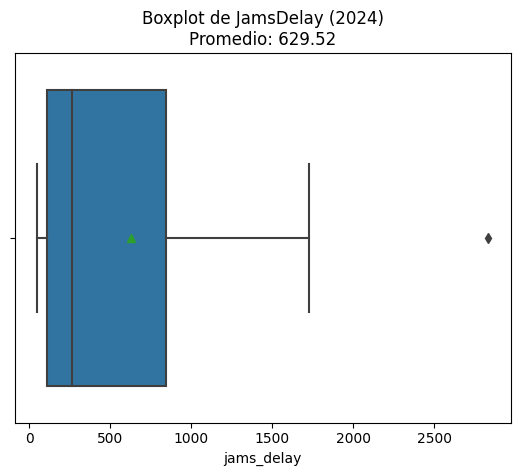

city                                   mexico-city
country                                        MEX
year                                          2024
jams_delay                             2833.057892
traffic_index_live                        34.21819
jams_length_in_kms                      389.239265
jams_count                              594.969392
mins_delay                                1.855542
travel_time_live_per_10kms_mins          21.809092
travel_time_historic_per_10kms_mins       19.95355
city_gdp_capita                            21111.0
unemployment_pct                               3.2
pm25_ug_m3                                   22,30
population                              22100000.0
Name: 7, dtype: object


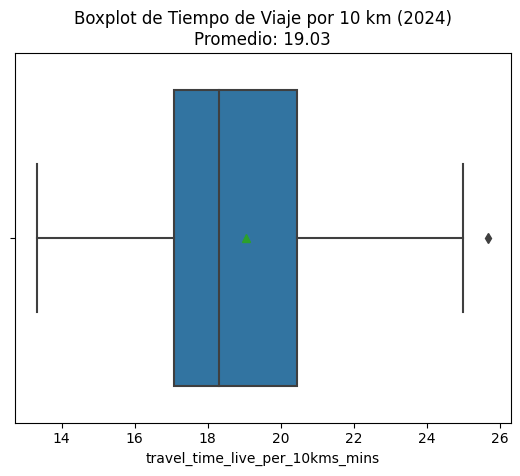

           city country  travel_time_live_per_10kms_mins
6          lima     PER                        25.674261
1        bogota     COL                        24.992185
7   mexico-city     MEX                        21.809092
14    sao-paulo     BRA                        20.801836
10       recife     BRA                        20.101569


In [ ]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay


sns.boxplot(x=merged['jams_delay'],showmeans=True)

# Ese punto negro en el extremo derecho (cerca de 2800) es un valor atípico (outlier) muy marcado
# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title('Boxplot de JamsDelay (2024)\nPromedio: ' + str(round(mean_value, 2)))
plt.show()

print (merged.loc[merged['jams_delay'].idxmax()])

sns.boxplot(x=merged['travel_time_live_per_10kms_mins'], showmeans=True)

# Promedio de minutos por cada 10 km
mean_time = merged['travel_time_live_per_10kms_mins'].mean()
plt.title('Boxplot de Tiempo de Viaje por 10 km (2024)\nPromedio: ' + str(round(mean_time, 2)))
plt.show()

# Mostrar las 2 ciudades más lentas (Lima y Bogotá)
print(merged.nlargest(5, 'travel_time_live_per_10kms_mins')[['city', 'country', 'travel_time_live_per_10kms_mins']])


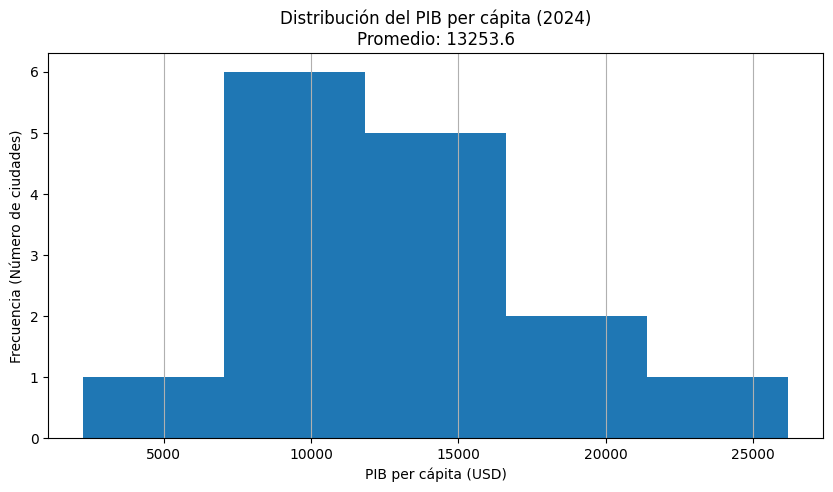

city                                   montevideo
country                                       URY
year                                         2024
jams_delay                              50.201092
traffic_index_live                      17.014854
jams_length_in_kms                       6.369201
jams_count                              14.160332
mins_delay                               0.393442
travel_time_live_per_10kms_mins         18.892342
travel_time_historic_per_10kms_mins       18.4989
city_gdp_capita                           26176.0
unemployment_pct                              8.4
pm25_ug_m3                                  11,20
population                              1800000.0
Name: 8, dtype: object
city                                     santiago
country                                       CHL
year                                         2024
jams_delay                             629.865318
traffic_index_live                      20.155352
jams_length_in_kms         

,city,country,city_gdp_capita,jams_delay
8,montevideo,URY,26176.0,50.201092
7,mexico-city,MEX,21111.0,2833.057892
3,buenos-aires,ARG,18117.0,571.089593
2,brasilia,BRA,16251.0,101.576326
14,sao-paulo,BRA,14703.0,1729.189270
6,lima,PER,13472.0,1052.292789
11,rio-de-janeiro,BRA,13349.0,466.064706
4,curitiba,BRA,12381.0,183.469274
9,porto-alegre,BRA,11801.0,139.382830
1,bogota,COL,11442.0,1141.552364


In [ ]:
# Crear histograma para ver la distribución de la economía

merged["city_gdp_capita"].hist(bins=5, figsize=(10, 5))

mean_gdp = merged['city_gdp_capita'].mean()
plt.title('Distribución del PIB per cápita (2024)\nPromedio: ' + str(round(mean_gdp, 2)))
plt.xlabel('PIB per cápita (USD)')
plt.ylabel('Frecuencia (Número de ciudades)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

print (merged.loc[merged['city_gdp_capita'].idxmax()])
print (merged.loc[merged['city_gdp_capita'].idxmin()])
merged[['city', 'country', 'city_gdp_capita', 'jams_delay']].sort_values(by='city_gdp_capita', ascending=False).head(15)

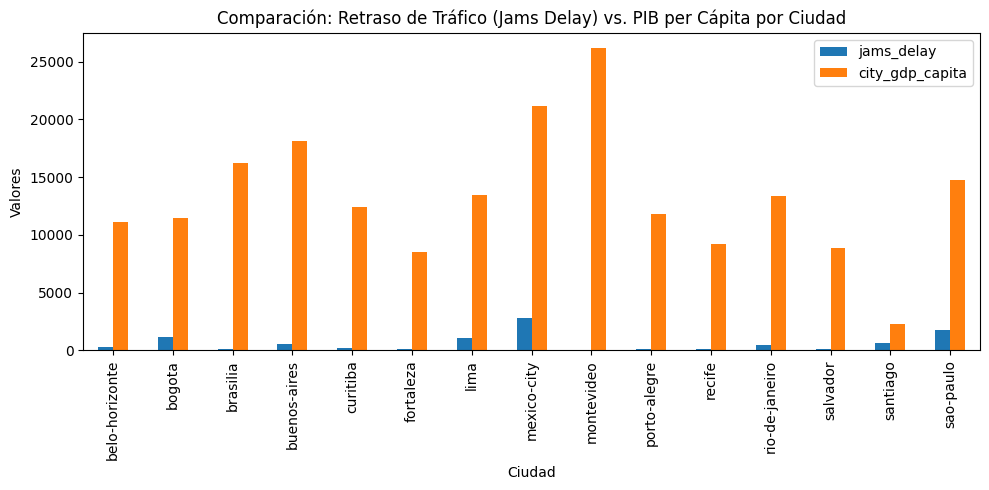

In [ ]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
import matplotlib.pyplot as plt

# 1. Primer gráfico: Tráfico vs. PIB per cápita
merged.plot(x='city', y=['jams_delay', 'city_gdp_capita'], kind='bar', figsize=(10, 5))
plt.title('Comparación: Retraso de Tráfico (Jams Delay) vs. PIB per Cápita por Ciudad')
plt.xlabel('Ciudad')
plt.ylabel('Valores')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()





**Tip:** Antes del `plt.show()` agrega el código `plt.xticks(rotation=90)` para rotar las etiquetas del eje X en 90 grados.

### 🧠 **Reflexiona**
Excelente trabajo llegando a esta etapa del análisis. Antes de avanzar, revisa tus gráficos, tómate un momento para pensar:

* ¿Las ciudades con mayor PIB per cápita también presentan más congestión?

* ¿O sucede lo contrario, o no existe una relación clara?

Escribe tus comentarios: No existe una relacion clara entre PIB per cápita y ciudades con mayor nivel de congestión porque por ejemplo Montevideo y Brasilia tienen unos altisimos  valores de PIB per capita y bajas barras de tráfico.Incluso Santiago que presenta bajo valor de PIB per cápita presenta una tendencia de tráfico bastante alta.
Las ciudades con mayor tráfico son Mexico, Bogotá, lima, Sao Paulo, Santiago. La diferencia entre la ciudad con mayor tráfico que es México y la segunda que es Sao Paulo es muy alta. Pasa de 2833.05 en Mexico contra 1729.18 en Sao Paulo, es decir un 63% de diferencia.
Tampoco pareciera que si usamos la métrica de desempleo tenga una correlación con las ciudades de mayor tráfico.


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [ ]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

Para poder ver o descargar el archivo generado:   
En el menú lateral que esta a la izquierda, ve hasta la parte de abajo, a la sección de **Exportar dataset** para más información.


---

## ✅ Entregables

1. **Notebook `.ipynb`** con todas las celdas (código + comentarios).
2. **CSV final**: `ladb_mobility_economy_2024_clean.csv`.
3. **Resumen ejecutivo breve** en Markdown (3–5 párrafos).


# 🧾 Resumen ejecutivo

> Este resumen presenta los resultados del análisis comparativo entre movilidad urbana e indicadores económicos y ambientales para 15 ciudades de América Latina.

**Contexto & objetivo:**

El análisis buscó determinar si existe una relación directa entre el nivel de congestión vehicular y la productividad económica por habitante. Se integraron dos bases de datos: una con registros de tráfico en tiempo real y otra con indicadores macroeconómicos y ambientales, contrastando el Producto Interno Bruto (PIB) per cápita frente a los retrasos viales.

Los resultados confirmaron que **no existe una relación lineal directa** entre ambas variables. Una mayor riqueza por habitante no garantiza vías más despejadas, y la congestión responde principalmente a la escala demográfica y a la falta de transporte masivo antes que al PIB.

* **Variables clave utilizadas:**
* **`jams_delay` (Retraso total por congestión en minutos):** Mide el tiempo total perdido por los conductores debido al tráfico detenido o lento. Es fundamental para cuantificar las horas-hombre que pierde una ciudad al año.
* **`travel_time_live_per_10kms_mins` (Tiempo para recorrer 10 km):** Refleja la velocidad media y la lentitud real del sistema de transporte.
* **`city_gdp_capita` (PIB per cápita en USD):** Indica el nivel de productividad económica media de la población.

---

**Cobertura de datos:**

* **Año evaluado:** 2024
* **Países incluidos:** 7 (Argentina, Brasil, Chile, Colombia, México, Perú y Uruguay)
* **Ciudades analizadas:** 15 metrópolis

---

**Metodología (alto nivel):**

* **Limpieza y estandarización:** Se corrigieron formatos numéricos (reemplazo de comas decimales por puntos), se transformaron fechas a tipo `datetime` y se estandarizaron los nombres de las columnas en minúsculas para homologar ambas fuentes.
* **Agregación y unión:** Se promediaron los datos de tráfico a nivel anual por ciudad (`groupby`) y se aplicó una unión `INNER JOIN` usando como clave `city`, `country` y `year`, asegurando que solo se conservaran ciudades con información completa en ambas fuentes.
* **Validaciones visuales:**
* **Boxplot de `jams_delay`:** Permitió identificar a Ciudad de México como un valor atípico (*outlier*) extremo por el volumen acumulado de embotellamientos.

* **Boxplot de tiempo por 10 km:** Mostró que Lima (25.7 min) y Bogotá (25.0 min) se ubican en el extremo superior, muy por encima de la media de 19.0 minutos.

* **Histograma de PIB per cápita:** Evidenció la dispersión del ingreso, señalando a Montevideo como el extremo superior y a Santiago como un caso atípico en el rango inferior.

---

**Hallazgos principales:**

* **Falta de correlación directa:** Ciudades de ingresos altos pueden tener tráfico bajo (como Montevideo o Brasilia), mientras urbes de ingresos medios sufren severos colapsos viales.
* **Valores atípicos y anomalías detectadas:**
* **Ciudad de México:** Registra 2,833 minutos de retraso, superando por más de 63% al segundo lugar (São Paulo) debido a su escala demográfica superior a 22 millones de personas.
* **Lima y Bogotá:** Son las dos ciudades más lentas de la región para desplazarse (toman más de 25 minutos por cada 10 km frente al promedio regional de 19 minutos).
* **Montevideo:** Lidera el PIB per cápita con $26,176 USD (casi el doble de la media regional) y mantiene una de las congestiones más bajas de la muestra.
* **Santiago:** Registra apenas $2,277 USD en PIB per cápita, un valor anómalo frente a los estándares de la capital chilena que requiere revisión en la fuente de datos.

---

**Recomendaciones & plan de acción:**

* **Ciudad prioritaria número uno:** **Bogotá** se perfila como la urbe más urgente para inversión en infraestructura. Aunque Lima tiene un tiempo de recorrido ligeramente más lento por kilómetro, Bogotá combina un menor ingreso per cápita ($11,442 USD), mayor desempleo (10.0%) y una mayor acumulación total de retrasos (`jams_delay` de 1,141 min).

